In [3]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    average_precision_score
)

import matplotlib.pyplot as plt

In [4]:
import pandas as pd

churn_data = pd.read_csv(
    "../03_Data_Prepeation/03.DataPrepration/Customer_Churn_Prepared.csv",
    parse_dates=["ReferenceDate", "FirstPurchase", "LastPurchase"]
)

print("Dataset shape:", churn_data.shape)
print("\nColumns:")
print(churn_data.columns.tolist())

print("\nFirst 5 rows:")
display(churn_data.head())

Dataset shape: (10926, 14)

Columns:
['CustomerID', 'FirstPurchase', 'LastPurchase', 'TotalSpend', 'TotalUnits', 'UniqueProducts', 'ActiveDays', 'Frequency', 'AverageInvoiceValue', 'Recency', 'TenureDays', 'AverageDaysBetweenPurchases', 'ReferenceDate', 'Churn']

First 5 rows:


,CustomerID,FirstPurchase,LastPurchase,TotalSpend,TotalUnits,UniqueProducts,ActiveDays,Frequency,AverageInvoiceValue,Recency,TenureDays,AverageDaysBetweenPurchases,ReferenceDate,Churn
0,12346,2011-01-18 10:01:00,2011-01-18 10:01:00,77183.60,74215,1,1,1,77183.600000,134,0,NaN,2011-06-01,1
1,12347,2010-12-07 14:57:00,2011-04-07 10:43:00,1823.43,1117,63,3,3,607.810000,55,121,60.411806,2011-06-01,0
2,12348,2010-12-16 19:09:00,2011-04-05 10:47:00,1487.24,2124,22,3,3,495.746667,57,110,54.825694,2011-06-01,1
3,12350,2011-02-02 16:01:00,2011-02-02 16:01:00,334.40,197,17,1,1,334.400000,119,0,NaN,2011-06-01,1
4,12352,2011-02-16 12:33:00,2011-03-22 16:08:00,1561.81,254,26,4,5,312.362000,71,34,8.537326,2011-06-01,1


In [5]:
print("Dataset information:")
churn_data.info()

print("\nMissing values per column:")
print(churn_data.isnull().sum())

print("\nTarget distribution:")
print(churn_data["Churn"].value_counts())

print("\nTarget distribution (percentage):")
print(
    (churn_data["Churn"].value_counts(normalize=True) * 100)
    .round(2)
)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 10926 entries, 0 to 10925
Data columns (total 14 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   CustomerID                   10926 non-null  int64         
 1   FirstPurchase                10926 non-null  datetime64[us]
 2   LastPurchase                 10926 non-null  datetime64[us]
 3   TotalSpend                   10926 non-null  float64       
 4   TotalUnits                   10926 non-null  int64         
 5   UniqueProducts               10926 non-null  int64         
 6   ActiveDays                   10926 non-null  int64         
 7   Frequency                    10926 non-null  int64         
 8   AverageInvoiceValue          10926 non-null  float64       
 9   Recency                      10926 non-null  int64         
 10  TenureDays                   10926 non-null  int64         
 11  AverageDaysBetweenPurchases  57

In [6]:
import pandas as pd

model_data = churn_data.loc[
    churn_data["ReferenceDate"] == pd.Timestamp("2011-06-01")
].copy()

feature_columns = [
    "TotalSpend",
    "TotalUnits",
    "UniqueProducts",
    "ActiveDays",
    "Frequency",
    "AverageInvoiceValue",
    "Recency",
    "TenureDays",
    "AverageDaysBetweenPurchases"
]

X = model_data[feature_columns].copy()
y = model_data["Churn"].copy()

print("Modeling dataset shape:", model_data.shape)
print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts())

Modeling dataset shape: (2659, 14)
Features shape: (2659, 9)
Target shape: (2659,)

Target distribution:
Churn
0    1331
1    1328
Name: count, dtype: int64


In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

X_train shape: (2127, 9)
X_test shape: (532, 9)
y_train shape: (2127,)
y_test shape: (532,)

Training target distribution:
Churn
0    1065
1    1062
Name: count, dtype: int64

Testing target distribution:
Churn
0    266
1    266
Name: count, dtype: int64


In [8]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier


rf_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median",
            add_indicator=True
        )
    ),
    (
        "model",
        RandomForestClassifier(
            n_estimators=200,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        )
    )
])

print(rf_pipeline)

Pipeline(steps=[('imputer',
                 SimpleImputer(add_indicator=True, strategy='median')),
                ('model',
                 RandomForestClassifier(min_samples_leaf=2, n_estimators=200,
                                        n_jobs=-1, random_state=42))])


In [9]:
rf_pipeline.fit(X_train, y_train)

print("Random Forest training completed.")

Random Forest training completed.


In [10]:
y_pred = rf_pipeline.predict(X_test)

print("First 20 actual labels:")
print(y_test.head(20).to_list())

print("\nFirst 20 predicted labels:")
print(y_pred[:20])

print("\nNumber of predictions:", len(y_pred))

First 20 actual labels:
[0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1]

First 20 predicted labels:
[1 1 1 0 0 0 0 0 0 0 0 0 0 1 0 1 0 0 0 1]

Number of predictions: 532


Classification Report:
              precision    recall  f1-score   support

No Churn (0)       0.69      0.64      0.66       266
   Churn (1)       0.66      0.71      0.69       266

    accuracy                           0.68       532
   macro avg       0.68      0.68      0.68       532
weighted avg       0.68      0.68      0.68       532


Confusion Matrix:
[[170  96]
 [ 76 190]]


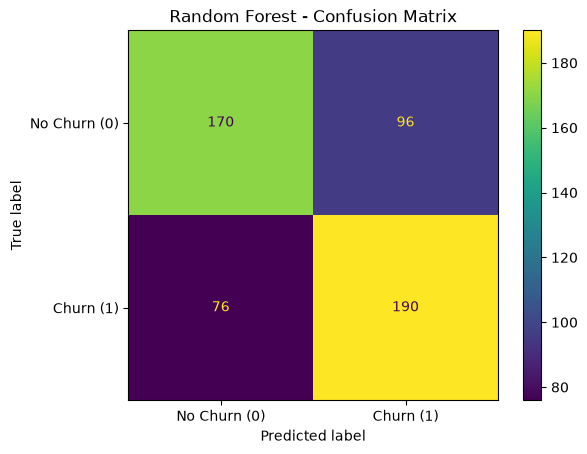

In [11]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt


print("Classification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Churn (0)", "Churn (1)"],
        zero_division=0
    )
)

cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn (0)", "Churn (1)"]
)

display.plot()
plt.title("Random Forest - Confusion Matrix")
plt.show()

In [12]:
from sklearn.metrics import roc_auc_score, average_precision_score


y_proba = rf_pipeline.predict_proba(X_test)[:, 1]

roc_auc = roc_auc_score(y_test, y_proba)

avg_precision = average_precision_score(y_test, y_proba)

print(f"ROC-AUC: {roc_auc:.4f}")
print(f"Average Precision: {avg_precision:.4f}")

ROC-AUC: 0.7114
Average Precision: 0.6664


In [13]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

rf_no_indicator = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "model",
        RandomForestClassifier(
            n_estimators=200,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        )
    )
])

rf_no_indicator.fit(X_train, y_train)

pred_no_indicator = rf_no_indicator.predict(X_test)
proba_no_indicator = rf_no_indicator.predict_proba(X_test)[:, 1]

print("Random Forest - Median Imputation Without Indicator")
print("Accuracy:", round(accuracy_score(y_test, pred_no_indicator), 4))
print("Precision:", round(
    precision_score(y_test, pred_no_indicator, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_test, pred_no_indicator, zero_division=0), 4
))
print("F1-score:", round(f1_score(y_test, pred_no_indicator, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, proba_no_indicator), 4))
print("Average Precision:", round(
    average_precision_score(y_test, proba_no_indicator), 4
))

Random Forest - Median Imputation Without Indicator
Accuracy: 0.6635
Precision: 0.6559
Recall: 0.688
F1-score: 0.6716
ROC-AUC: 0.7147
Average Precision: 0.6674


In [14]:
X_train_no_gap_feature = X_train.drop(
    columns=["AverageDaysBetweenPurchases"]
)

X_test_no_gap_feature = X_test.drop(
    columns=["AverageDaysBetweenPurchases"]
)

rf_without_gap_feature = Pipeline([
    (
        "model",
        RandomForestClassifier(
            n_estimators=200,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        )
    )
])

rf_without_gap_feature.fit(
    X_train_no_gap_feature,
    y_train
)

pred_without_gap_feature = rf_without_gap_feature.predict(
    X_test_no_gap_feature
)

proba_without_gap_feature = (
    rf_without_gap_feature
    .predict_proba(X_test_no_gap_feature)[:, 1]
)

print("Random Forest - Without AverageDaysBetweenPurchases")
print("Accuracy:", round(
    accuracy_score(y_test, pred_without_gap_feature), 4
))
print("Precision:", round(
    precision_score(y_test, pred_without_gap_feature, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_test, pred_without_gap_feature, zero_division=0), 4
))
print("F1-score:", round(
    f1_score(y_test, pred_without_gap_feature, zero_division=0), 4
))
print("ROC-AUC:", round(
    roc_auc_score(y_test, proba_without_gap_feature), 4
))
print("Average Precision:", round(
    average_precision_score(y_test, proba_without_gap_feature), 4
))

Random Forest - Without AverageDaysBetweenPurchases
Accuracy: 0.6654
Precision: 0.6528
Recall: 0.7068
F1-score: 0.6787
ROC-AUC: 0.7109
Average Precision: 0.6646


In [15]:
missing_gap = model_data["AverageDaysBetweenPurchases"].isna()

print("Total rows:", len(model_data))
print("Rows with missing gap:", missing_gap.sum())
print("Rows without missing gap:", (~missing_gap).sum())

print("\nFrequency distribution for rows with missing gap:")
print(model_data.loc[missing_gap, "Frequency"].value_counts().sort_index().head(10))

print("\nFrequency distribution for rows without missing gap:")
print(model_data.loc[~missing_gap, "Frequency"].value_counts().sort_index().head(10))

Total rows: 2659
Rows with missing gap: 1303
Rows without missing gap: 1356

Frequency distribution for rows with missing gap:
Frequency
1    1303
Name: count, dtype: int64

Frequency distribution for rows without missing gap:
Frequency
2     555
3     290
4     152
5     100
6      70
7      42
8      32
9      24
10     12
11     21
Name: count, dtype: int64


In [16]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logreg_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

logreg_pipeline.fit(X_train, y_train)

print("Logistic Regression training completed.")

Logistic Regression training completed.


In [17]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

y_pred_logreg = logreg_pipeline.predict(X_test)

y_proba_logreg = logreg_pipeline.predict_proba(X_test)[:, 1]

print("Logistic Regression Results")
print("-" * 35)

print("Accuracy:", round(accuracy_score(y_test, y_pred_logreg), 4))
print("Precision:", round(precision_score(y_test, y_pred_logreg), 4))
print("Recall:", round(recall_score(y_test, y_pred_logreg), 4))
print("F1-score:", round(f1_score(y_test, y_pred_logreg), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_proba_logreg), 4))
print("Average Precision:", round(
    average_precision_score(y_test, y_proba_logreg), 4
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_logreg))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_logreg))

Logistic Regression Results
-----------------------------------
Accuracy: 0.6861
Precision: 0.6656
Recall: 0.7481
F1-score: 0.7044
ROC-AUC: 0.7354
Average Precision: 0.6941

Confusion Matrix:
[[166 100]
 [ 67 199]]

Classification Report:
              precision    recall  f1-score   support

           0       0.71      0.62      0.67       266
           1       0.67      0.75      0.70       266

    accuracy                           0.69       532
   macro avg       0.69      0.69      0.68       532
weighted avg       0.69      0.69      0.68       532



In [18]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier

dt_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("model", DecisionTreeClassifier(
        random_state=42,
        min_samples_leaf=10
    ))
])

dt_pipeline.fit(X_train, y_train)

print("Decision Tree training completed.")

Decision Tree training completed.


In [19]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

y_pred_dt = dt_pipeline.predict(X_test)

y_proba_dt = dt_pipeline.predict_proba(X_test)[:, 1]

print("Decision Tree Results")
print("-" * 35)

print("Accuracy:", round(accuracy_score(y_test, y_pred_dt), 4))
print("Precision:", round(precision_score(y_test, y_pred_dt), 4))
print("Recall:", round(recall_score(y_test, y_pred_dt), 4))
print("F1-score:", round(f1_score(y_test, y_pred_dt), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_proba_dt), 4))
print("Average Precision:", round(
    average_precision_score(y_test, y_proba_dt), 4
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

Decision Tree Results
-----------------------------------
Accuracy: 0.6353
Precision: 0.6343
Recall: 0.6391
F1-score: 0.6367
ROC-AUC: 0.6779
Average Precision: 0.6313

Confusion Matrix:
[[168  98]
 [ 96 170]]

Classification Report:
              precision    recall  f1-score   support

           0       0.64      0.63      0.63       266
           1       0.63      0.64      0.64       266

    accuracy                           0.64       532
   macro avg       0.64      0.64      0.64       532
weighted avg       0.64      0.64      0.64       532



In [20]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import GradientBoostingClassifier

gb_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("model", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

gb_pipeline.fit(X_train, y_train)

print("Gradient Boosting training completed.")

Gradient Boosting training completed.


In [21]:
y_pred_gb = gb_pipeline.predict(X_test)
y_proba_gb = gb_pipeline.predict_proba(X_test)[:, 1]

print("Gradient Boosting Results")
print("-" * 35)

print("Accuracy:", round(accuracy_score(y_test, y_pred_gb), 4))
print("Precision:", round(precision_score(y_test, y_pred_gb), 4))
print("Recall:", round(recall_score(y_test, y_pred_gb), 4))
print("F1-score:", round(f1_score(y_test, y_pred_gb), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_proba_gb), 4))
print("Average Precision:", round(
    average_precision_score(y_test, y_proba_gb), 4
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_gb))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_gb))

Gradient Boosting Results
-----------------------------------
Accuracy: 0.6786
Precision: 0.6589
Recall: 0.7406
F1-score: 0.6973
ROC-AUC: 0.7255
Average Precision: 0.6536

Confusion Matrix:
[[164 102]
 [ 69 197]]

Classification Report:
              precision    recall  f1-score   support

           0       0.70      0.62      0.66       266
           1       0.66      0.74      0.70       266

    accuracy                           0.68       532
   macro avg       0.68      0.68      0.68       532
weighted avg       0.68      0.68      0.68       532



In [22]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Decision Tree",
        "Gradient Boosting"
    ],
    "Accuracy": [0.6861, 0.6767, 0.6353, 0.6786],
    "Precision": [0.6656, 0.6643, 0.6343, 0.6589],
    "Recall": [0.7481, 0.7143, 0.6391, 0.7406],
    "F1-score": [0.7044, 0.6884, 0.6367, 0.6973],
    "ROC-AUC": [0.7354, 0.7114, 0.6779, 0.7255],
    "Average Precision": [0.6941, 0.6664, 0.6313, 0.6536]
})

comparison = comparison.sort_values(
    by="F1-score",
    ascending=False
).reset_index(drop=True)

comparison

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
0,Logistic Regression,0.6861,0.6656,0.7481,0.7044,0.7354,0.6941
1,Gradient Boosting,0.6786,0.6589,0.7406,0.6973,0.7255,0.6536
2,Random Forest,0.6767,0.6643,0.7143,0.6884,0.7114,0.6664
3,Decision Tree,0.6353,0.6343,0.6391,0.6367,0.6779,0.6313


In [23]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "average_precision": "average_precision"
}

cv_results = cross_validate(
    logreg_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

for metric in scoring:
    scores = cv_results[f"test_{metric}"]
    print(
        f"{metric}: {scores.mean():.4f} "
        f"+/- {scores.std():.4f}"
    )

accuracy: 0.6911 +/- 0.0055
precision: 0.6670 +/- 0.0063
recall: 0.7627 +/- 0.0353
f1: 0.7111 +/- 0.0123
roc_auc: 0.7505 +/- 0.0084
average_precision: 0.6907 +/- 0.0102


In [24]:
from sklearn.model_selection import cross_validate

models = {
    "Logistic Regression": logreg_pipeline,
    "Random Forest": rf_pipeline,
    "Decision Tree": dt_pipeline,
    "Gradient Boosting": gb_pipeline
}

cv_comparison = []

for model_name, pipeline in models.items():
    results = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    row = {"Model": model_name}

    for metric in scoring:
        scores = results[f"test_{metric}"]
        row[f"{metric}_mean"] = scores.mean()
        row[f"{metric}_std"] = scores.std()

    cv_comparison.append(row)

cv_comparison = pd.DataFrame(cv_comparison)

cv_comparison.sort_values(
    by="f1_mean",
    ascending=False
).round(4)

,Model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std
0,Logistic Regression,0.6911,0.0055,0.6670,0.0063,0.7627,0.0353,0.7111,0.0123,0.7505,0.0084,0.6907,0.0102
3,Gradient Boosting,0.6869,0.0062,0.6646,0.0089,0.7542,0.0337,0.7060,0.0117,0.7362,0.0122,0.6847,0.0144
1,Random Forest,0.6732,0.0181,0.6594,0.0197,0.7166,0.0265,0.6864,0.0168,0.7335,0.0220,0.6880,0.0259
2,Decision Tree,0.6324,0.0164,0.6314,0.0204,0.6365,0.0223,0.6335,0.0137,0.6892,0.0282,0.6484,0.0292


In [25]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__class_weight": [None, "balanced"]
}

grid_search = GridSearchCV(
    estimator=logreg_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    refit=True
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation F1:", round(grid_search.best_score_, 4))

Best parameters: {'model__C': 100, 'model__class_weight': 'balanced'}
Best cross-validation F1: 0.7125


In [26]:
best_logreg = grid_search.best_estimator_

print("Optimized Logistic Regression is ready.")

Optimized Logistic Regression is ready.


In [27]:
y_pred_best = best_logreg.predict(X_test)
y_proba_best = best_logreg.predict_proba(X_test)[:, 1]

print("Optimized Logistic Regression Results")
print("-" * 40)

print("Accuracy:", round(accuracy_score(y_test, y_pred_best), 4))
print("Precision:", round(precision_score(y_test, y_pred_best), 4))
print("Recall:", round(recall_score(y_test, y_pred_best), 4))
print("F1-score:", round(f1_score(y_test, y_pred_best), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_proba_best), 4))
print("Average Precision:", round(
    average_precision_score(y_test, y_proba_best), 4
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_best))

Optimized Logistic Regression Results
----------------------------------------
Accuracy: 0.6917
Precision: 0.6689
Recall: 0.7594
F1-score: 0.7113
ROC-AUC: 0.7359
Average Precision: 0.6963

Confusion Matrix:
[[166 100]
 [ 64 202]]


In [28]:
from sklearn.model_selection import GridSearchCV

gb_param_grid = {
    "model__n_estimators": [100, 200],
    "model__learning_rate": [0.03, 0.1],
    "model__max_depth": [2, 3],
    "model__min_samples_leaf": [5, 10]
}

gb_grid_search = GridSearchCV(
    estimator=gb_pipeline,
    param_grid=gb_param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    refit=True
)

gb_grid_search.fit(X_train, y_train)

print("Best parameters:", gb_grid_search.best_params_)
print("Best cross-validation F1:", round(
    gb_grid_search.best_score_, 4
))

Best parameters: {'model__learning_rate': 0.03, 'model__max_depth': 2, 'model__min_samples_leaf': 10, 'model__n_estimators': 100}
Best cross-validation F1: 0.7143


In [29]:
best_gb = gb_grid_search.best_estimator_

print("Optimized Gradient Boosting is ready.")

Optimized Gradient Boosting is ready.


In [30]:
y_pred_gb_best = best_gb.predict(X_test)
y_proba_gb_best = best_gb.predict_proba(X_test)[:, 1]

print("Optimized Gradient Boosting Results")
print("-" * 40)

print("Accuracy:", round(
    accuracy_score(y_test, y_pred_gb_best), 4
))
print("Precision:", round(
    precision_score(y_test, y_pred_gb_best), 4
))
print("Recall:", round(
    recall_score(y_test, y_pred_gb_best), 4
))
print("F1-score:", round(
    f1_score(y_test, y_pred_gb_best), 4
))
print("ROC-AUC:", round(
    roc_auc_score(y_test, y_proba_gb_best), 4
))
print("Average Precision:", round(
    average_precision_score(y_test, y_proba_gb_best), 4
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_gb_best))

Optimized Gradient Boosting Results
----------------------------------------
Accuracy: 0.6711
Precision: 0.6482
Recall: 0.7481
F1-score: 0.6946
ROC-AUC: 0.7325
Average Precision: 0.6746

Confusion Matrix:
[[158 108]
 [ 67 199]]


In [31]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)
import pandas as pd

models = {
    "Logistic Regression (Tuned)": best_logreg,
    "Gradient Boosting (Tuned)": best_gb,
    "Random Forest": rf_pipeline,
    "Decision Tree": dt_pipeline
}

results = []

for model_name, pipeline in models.items():
    y_pred = pipeline.predict(X_test)
    y_proba = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba),
        "Average Precision": average_precision_score(y_test, y_proba)
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1-score",
    ascending=False
).reset_index(drop=True)

results_df.round(4)


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
0,Logistic Regression (Tuned),0.6917,0.6689,0.7594,0.7113,0.7359,0.6963
1,Gradient Boosting (Tuned),0.6711,0.6482,0.7481,0.6946,0.7325,0.6746
2,Random Forest,0.6767,0.6643,0.7143,0.6884,0.7114,0.6664
3,Decision Tree,0.6353,0.6343,0.6391,0.6367,0.6779,0.6313


In [32]:

import pandas as pd

imputer = rf_pipeline.named_steps["imputer"]

feature_names = imputer.get_feature_names_out(feature_columns)

importances = rf_pipeline.named_steps["model"].feature_importances_

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

feature_importance_df.round(4)


,Feature,Importance
0,TotalSpend,0.1566
1,TotalUnits,0.1528
2,Recency,0.1375
3,AverageInvoiceValue,0.1272
4,UniqueProducts,0.1214
5,TenureDays,0.1067
6,ActiveDays,0.0656
7,Frequency,0.0573
8,AverageDaysBetweenPurchases,0.0533
9,missingindicator_AverageDaysBetweenPurchases,0.0216


In [33]:
from sklearn.inspection import permutation_importance
import pandas as pd

perm_result = permutation_importance(
    best_logreg,
    X_test,
    y_test,
    scoring="f1",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance_Mean": perm_result.importances_mean,
    "Importance_Std": perm_result.importances_std
})

permutation_df = permutation_df.sort_values(
    by="Importance_Mean",
    ascending=False
).reset_index(drop=True)

permutation_df.round(4)


,Feature,Importance_Mean,Importance_Std
0,ActiveDays,0.1316,0.0178
1,UniqueProducts,0.0243,0.0057
2,AverageDaysBetweenPurchases,0.0188,0.0061
3,Frequency,0.0176,0.0114
4,TotalUnits,0.0073,0.0052
5,TenureDays,0.0035,0.0066
6,Recency,0.0021,0.0071
7,AverageInvoiceValue,0.0014,0.0024
8,TotalSpend,0.0002,0.0007


In [34]:
import pandas as pd

best_logreg_model = best_logreg.named_steps["model"]
imputer = best_logreg.named_steps["imputer"]
scaler = best_logreg.named_steps["scaler"]

feature_names = imputer.get_feature_names_out(feature_columns)

coefficients = best_logreg_model.coef_[0]

coefficient_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

coefficient_df["AbsoluteCoefficient"] = (
    coefficient_df["Coefficient"].abs()
)

coefficient_df = coefficient_df.sort_values(
    by="AbsoluteCoefficient",
    ascending=False
).reset_index(drop=True)

coefficient_df.round(4)


,Feature,Coefficient,AbsoluteCoefficient
0,ActiveDays,-2.1076,2.1076
1,Frequency,1.2868,1.2868
2,TotalUnits,-0.4173,0.4173
3,UniqueProducts,-0.3561,0.3561
4,AverageInvoiceValue,0.2712,0.2712
5,TenureDays,-0.2322,0.2322
6,AverageDaysBetweenPurchases,0.1972,0.1972
7,Recency,0.1629,0.1629
8,missingindicator_AverageDaysBetweenPurchases,0.1535,0.1535
9,TotalSpend,-0.0387,0.0387


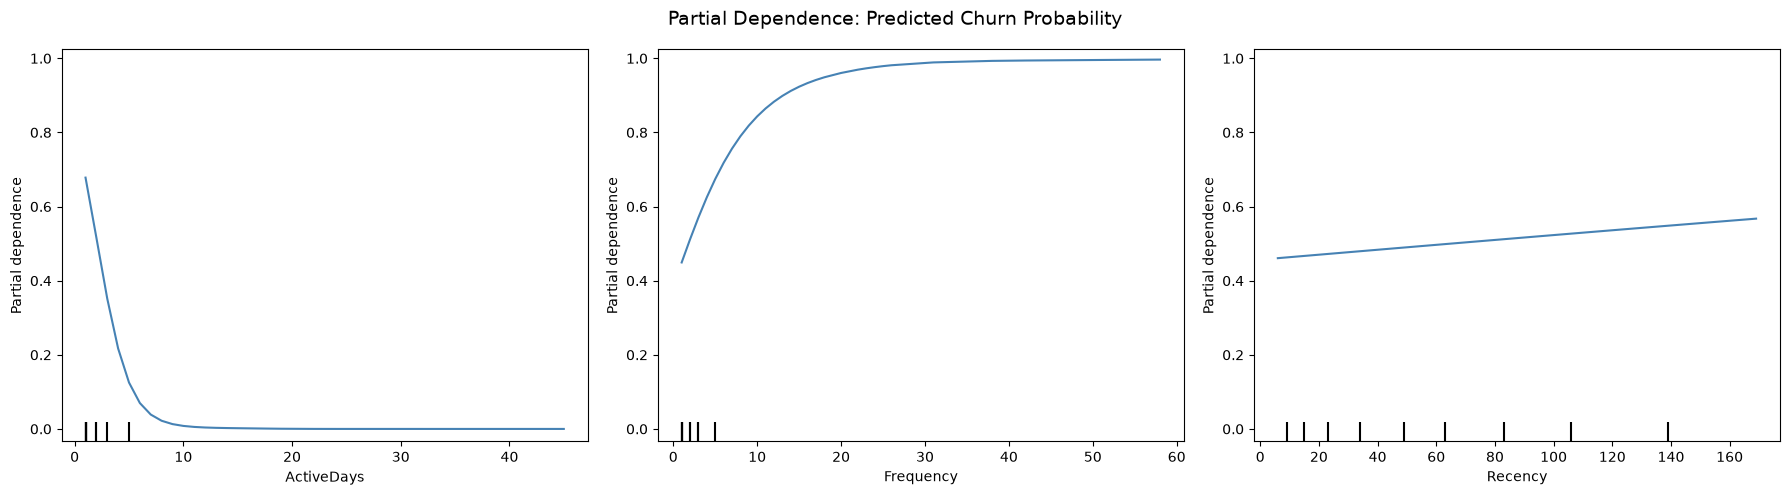

In [35]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.inspection import PartialDependenceDisplay

features_to_plot = [
    "ActiveDays",
    "Frequency",
    "Recency"
]

X_train_plot = X_train.copy()

X_train_plot[features_to_plot] = (
    X_train_plot[features_to_plot].astype(float)
)

fig, ax = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(18, 5)
)

PartialDependenceDisplay.from_estimator(
    best_logreg,
    X_train_plot,
    features=features_to_plot,
    response_method="predict_proba",
    ax=ax,
    line_kw={"color": "steelblue"}
)

fig.suptitle(
    "Partial Dependence: Predicted Churn Probability",
    fontsize=14
)

plt.tight_layout()
plt.show()
